In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import os
import joblib

In [2]:
### Read CSV
df = pd.read_csv('uber.csv')
print(df.shape)
print(df.info())
print(df.columns)
df.head()

(200000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB
None
Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='str')


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
print(df.isnull().sum())  

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [4]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [5]:
### drop unneeded columns
df = df.drop(columns=['Unnamed: 0', 'key'])

In [6]:
### Clean the bad rows
print("Before:", df.shape[0])

df = df.dropna()
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= 100)]
df = df[df['passenger_count'].between(1, 6)]
df = df[df['pickup_latitude'].between(40, 42) & df['dropoff_latitude'].between(40, 42) &
        df['pickup_longitude'].between(-75, -72) & df['dropoff_longitude'].between(-75, -72)]
print("After :", df.shape[0])

Before: 200000
After : 195022


In [7]:
#### Make columns from the date
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['weekday'] = df['pickup_datetime'].dt.day_of_week
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year

df = df.drop(columns=['pickup_datetime'])


In [8]:
### Make the distance column (the most useful one)
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371                                      
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlambda / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine_km(df['pickup_latitude'], df['pickup_longitude'],
                                 df['dropoff_latitude'], df['dropoff_longitude'])

In [9]:
#### Remove impossible distances
print((df['distance_km'] == 0).sum(), (df['distance_km'] > 100).sum())

df = df[(df['distance_km'] > 0) & (df['distance_km'] < 100)]
print(df.shape)

2030 4
(192988, 12)


In [10]:
### Split the data into features and target variable
X = df.drop(columns=['fare_amount'])
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.select_dtypes(include=['object']).columns)

Index([], dtype='str')


In [11]:
### Baseline (the score to beat) with the mean of the target variable
baseline = np.full(len(y_test), y_train.mean())
print("Baseline MAE:", round(mean_absolute_error(y_test, baseline), 3))

print(X_train.select_dtypes(include=['object']).columns)

Baseline MAE: 5.947
Index([], dtype='str')


In [12]:
### Train a tree with no limit on depth
free_tree = DecisionTreeRegressor(random_state=42)
free_tree.fit(X_train, y_train)

print('Depth: ', free_tree.get_depth())
print('Train R2: ', round(free_tree.score(X_train, y_train), 4))
print('Test R2: ', round(free_tree.score(X_test, y_test), 4))



Depth:  45
Train R2:  1.0
Test R2:  0.7361


In [ ]:
### Find the best depth using cross-validation
cv_scores = []
for d in range(1, 16):
    t = DecisionTreeRegressor(max_depth=d, random_state=42)
    cv_scores.append(cross_val_score(t, X_train, y_train, cv=5, scoring='r2').mean())

plt.plot(range(1, 16), cv_scores, marker='o')
plt.xlabel('Max Depth')
plt.ylabel('CV R2 Score') 
plt.show()

best_depth = int(np.argmax(cv_scores)) + 1
print("Best depth:", best_depth)

In [ ]:
### Train the final model with the best depth
final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
final_tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [ ]:
### Predict and evaluate the final model
y_pred = final_tree.predict(X_test)
print("Final Model MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("Final Model RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("Final Model R2:", round(r2_score(y_test, y_pred), 4))   
print("Train R2:", round(final_tree.score(X_train, y_train), 4))
print("Test R2:", round(final_tree.score(X_test, y_test), 4))

error_pedc = np.abs(y_test - y_pred) / y_test * 100
print('Within 10%:', round((error_pedc <= 10).mean() * 100, 1), "% of rides")
print('Within 20%:', round((error_pedc <= 20).mean() * 100, 1), "% of rides")


Final Model MAE: 1.986
Final Model RMSE: 3.742
Final Model R2: 0.8432
Train R2: 0.8662
Test R2: 0.8432
Within 10%: 35.0 % of rides
Within 20%: 63.9 % of rides


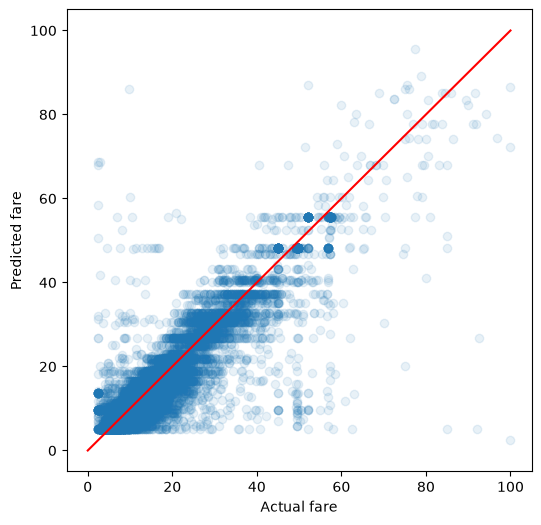

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.1)
plt.plot([0, 100], [0, 100], color='red')
plt.xlabel('Actual fare')
plt.ylabel('Predicted fare')
plt.show()

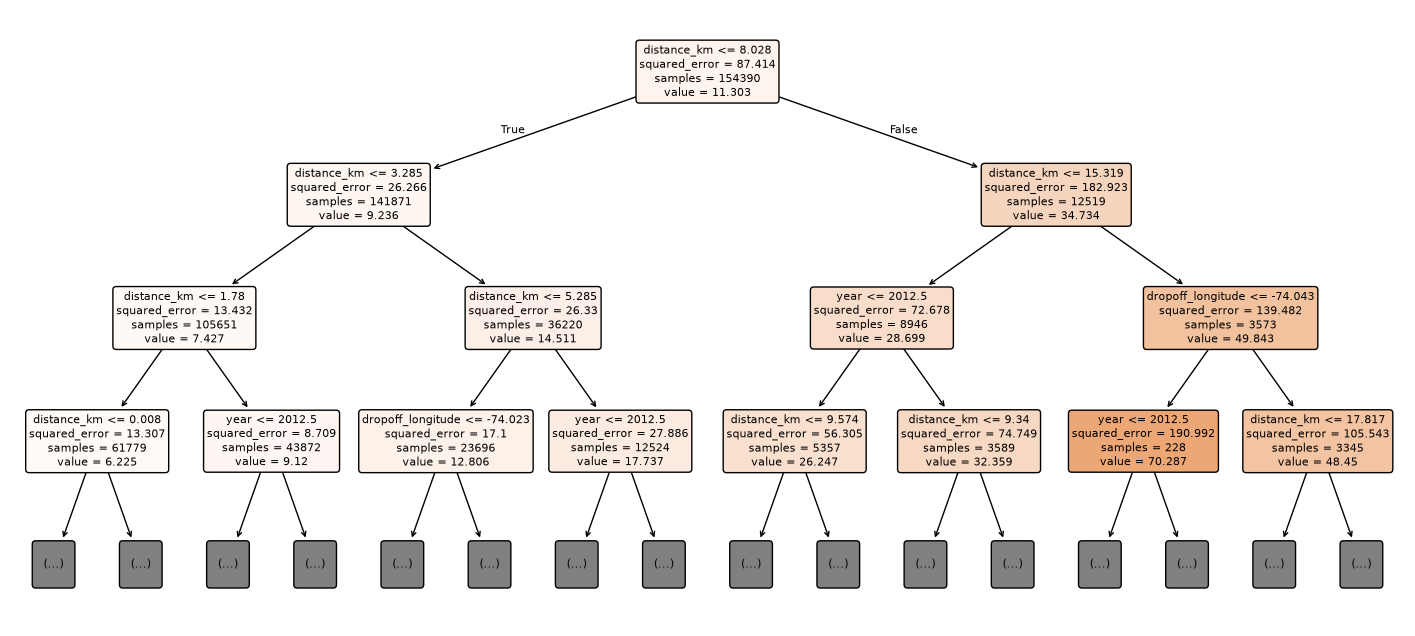

In [ ]:
plt.figure(figsize=(18, 8))
plot_tree(final_tree, feature_names=X.columns, filled=True, rounded=True,
          fontsize=8, max_depth=3)
plt.show()

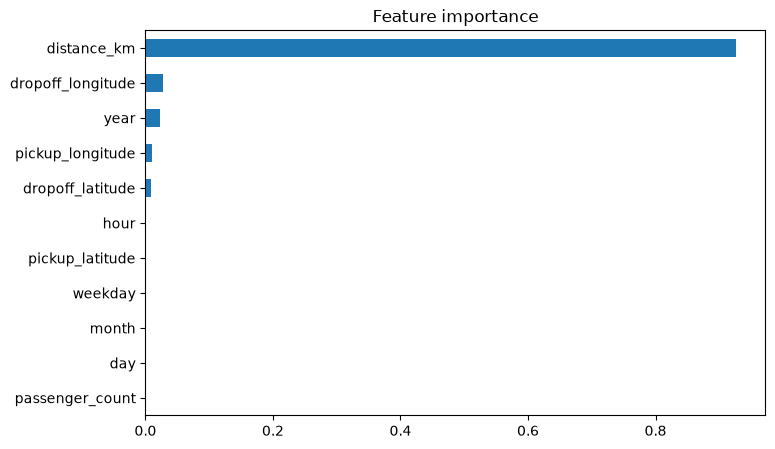

In [ ]:
imp = pd.Series(final_tree.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 5))
plt.title('Feature importance')
plt.show()

In [ ]:
### Pre-save check
y_pred = final_tree.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())

checks = {
    'No missing values in X': X.isnull().sum().sum() == 0,
    'No text columns in X': len(X.select_dtypes(exclude='number').columns) == 0,
    "'Unnamed: 0' and 'key' not in X": not {'Unnamed: 0', 'key'} & set(X.columns),
    "'fare_amount' not in X (target not leaked)": 'fare_amount' not in X.columns,
    'Fares between 0 and 100': (y.min() > 0) and (y.max() <= 100),
    'Passengers between 1 and 6': X['passenger_count'].between(1, 6).all(),
    'Coordinates inside New York area': (X['pickup_latitude'].between(40, 42) & X['dropoff_latitude'].between(40, 42) &
                                         X['pickup_longitude'].between(-75, -72) & X['dropoff_longitude'].between(-75, -72)).all(),
    'Distance between 0 and 100 km': ((X['distance_km'] > 0) & (X['distance_km'] < 100)).all(),
    'X has 11 columns': X.shape[1] == 11,
    'Final tree depth is 8 or less': final_tree.get_depth() <= 8,
    'Train and test R2 gap below 0.05': abs(final_tree.score(X_train, y_train) - final_tree.score(X_test, y_test)) < 0.05,
    'Test R2 above 0.80 (about 0.84 expected)': final_tree.score(X_test, y_test) > 0.80,
    'MAE better than the baseline': mean_absolute_error(y_test, y_pred) < mean_absolute_error(y_test, baseline),
}

for name, ok in checks.items():
    print("OK     " if ok else "PENDING", "-", name)

print()
print("Rows:", len(X), "| Test R2:", round(final_tree.score(X_test, y_test), 4),
      "| Test MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("ALL DONE, safe to save" if all(checks.values()) else "Fix the PENDING items first")

OK      - No missing values in X
OK      - No text columns in X
OK      - 'Unnamed: 0' and 'key' not in X
OK      - 'fare_amount' not in X (target not leaked)
OK      - Fares between 0 and 100
OK      - Passengers between 1 and 6
OK      - Coordinates inside New York area
OK      - Distance between 0 and 100 km
OK      - X has 11 columns
OK      - Final tree depth is 8 or less
OK      - Train and test R2 gap below 0.05
OK      - Test R2 above 0.80 (about 0.84 expected)
OK      - MAE better than the baseline

Rows: 192988 | Test R2: 0.8432 | Test MAE: 1.986
ALL DONE, safe to save


In [ ]:

### Save
joblib.dump({
    'model': final_tree,
    'columns': list(X.columns),      # exact column order used for training
}, 'uber_model.pkl')
print("Saved: uber_model.pkl")
print("File size:", os.path.getsize('uber_model.pkl'), "bytes")

### Load back and compare
saved = joblib.load('uber_model.pkl')
loaded_tree = saved['model']
print("Same predictions on X_test:", np.array_equal(final_tree.predict(X_test), loaded_tree.predict(X_test)))
print("Loaded test R2            :", round(loaded_tree.score(X_test, y_test), 4))
print("Number of columns         :", len(saved['columns']))

### Helper that prepares a new ride
def prepare_ride(raw_df, saved):
    d = raw_df.copy()
    d['pickup_datetime'] = pd.to_datetime(d['pickup_datetime'])
    d['hour'] = d['pickup_datetime'].dt.hour
    d['day'] = d['pickup_datetime'].dt.day
    d['weekday'] = d['pickup_datetime'].dt.day_of_week
    d['month'] = d['pickup_datetime'].dt.month
    d['year'] = d['pickup_datetime'].dt.year
    d['distance_km'] = haversine_km(d['pickup_latitude'], d['pickup_longitude'],
                                    d['dropoff_latitude'], d['dropoff_longitude'])
    return d[saved['columns']]

### Raw rides must give the same predictions as the training data
raw = pd.read_csv('uber.csv')
X_check = prepare_ride(raw.loc[X.index[:500]], saved)
print("Same predictions from raw rides:",
      np.array_equal(loaded_tree.predict(X_check), final_tree.predict(X.iloc[:500])))

### Predict one new ride (Times Square to JFK airport)
new_ride = {
    'pickup_datetime': '2015-06-15 18:30:00 UTC',
    'pickup_longitude': -73.9855, 'pickup_latitude': 40.7580,
    'dropoff_longitude': -73.7781, 'dropoff_latitude': 40.6413,
    'passenger_count': 1,
}
ride = prepare_ride(pd.DataFrame([new_ride]), saved)
print("Distance (km):", round(ride['distance_km'].iloc[0], 1))
print("Predicted fare: $", round(loaded_tree.predict(ride)[0], 2))

Saved: uber_model.pkl
File size: 34930 bytes
Same predictions on X_test: True
Loaded test R2            : 0.8432
Number of columns         : 11
Same predictions from raw rides: True
Distance (km): 21.8
Predicted fare: $ 55.53
